# percentile method


In [24]:
# Dependencies 

import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
plt.style.use('dark_background')

In [25]:
#  data

df = pd.read_csv('weight-height.csv')

In [26]:
df.head()

,Gender,Height,Weight
0,Male,73.847017,241.893563
1,Male,68.781904,162.310473
2,Male,74.110105,212.740856
3,Male,71.730978,220.042470
4,Male,69.881796,206.349801


In [27]:
df.describe()

,Height,Weight
count,10000.000000,10000.000000
mean,66.367560,161.440357
std,3.847528,32.108439
min,54.263133,64.700127
25%,63.505620,135.818051
50%,66.318070,161.212928
75%,69.174262,187.169525
max,78.998742,269.989699


In [28]:
df[['Height','Weight']].skew()

Height    0.049369
Weight    0.032955
dtype: float64

both are very close to normal

<Axes: xlabel='Weight'>

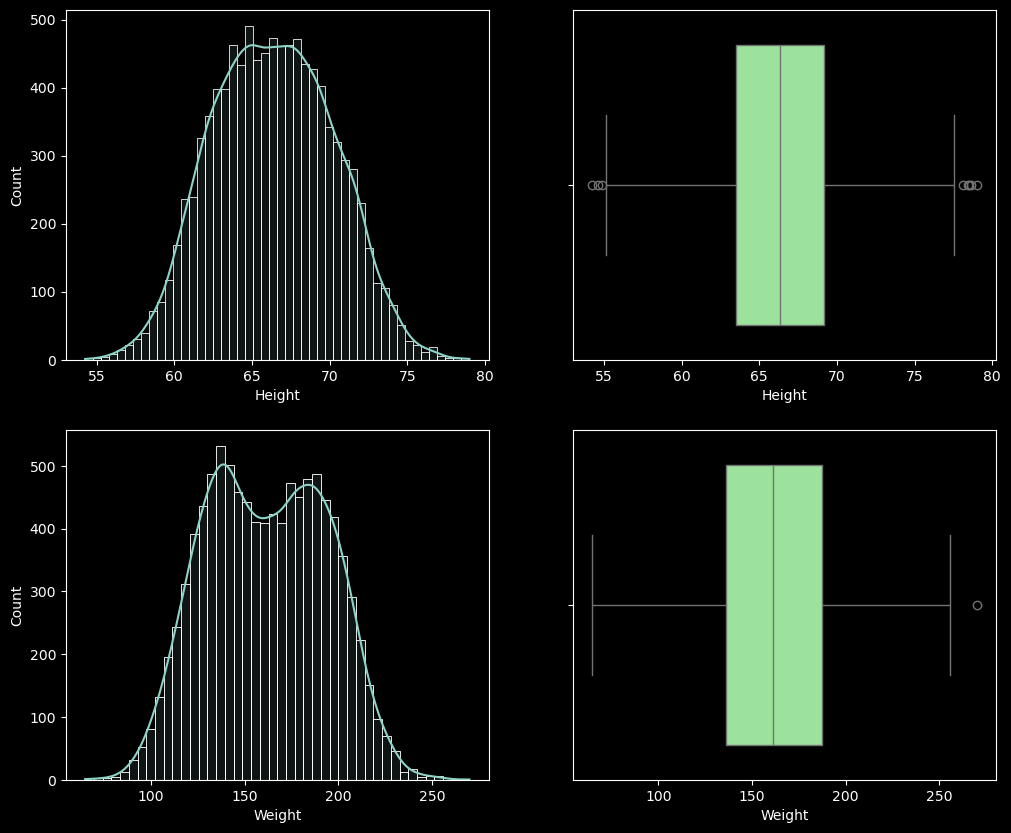

In [29]:
# plot


plt.figure(figsize=(12,10))
plt.subplot(2,2,1)
sns.histplot(df['Height'],kde=True, alpha=0.1)

plt.subplot(2,2,2)
sns.boxplot(df['Height'], orient='h',color='lightgreen')

plt.subplot(2,2,3)
sns.histplot(df['Weight'],kde=True, alpha=0.1)

plt.subplot(2,2,4)
sns.boxplot(df['Weight'], orient='h',color='lightgreen')




as we can see there is only 1 outlier as per boxplot in weight col , so lets focus on height col

In [30]:
upper_limit = df['Height'].quantile(0.99)
lower_limit = df['Height'].quantile(0.01)

In [31]:
upper_limit

74.7857900583366

In [32]:
lower_limit

58.13441158671655

In [33]:
df.shape

(10000, 3)

In [34]:
# filter

df[(df['Height'] > upper_limit) | (df['Height'] < lower_limit)]

,Gender,Height,Weight
23,Male,75.205974,228.761781
190,Male,76.709835,235.035419
197,Male,75.944460,231.924749
202,Male,75.140821,224.124271
215,Male,74.795375,232.635403
...,...,...,...
9761,Female,56.975279,90.341784
9825,Female,55.979198,85.417534
9895,Female,57.740192,93.652957
9904,Female,57.028857,101.202551


as we can see there are 200 outliters 


# trimming

In [35]:
trimmed_df = df[(df['Height'] < upper_limit) & (df['Height'] > lower_limit)]

In [36]:
trimmed_df.shape

(9800, 3)

In [37]:
trimmed_df.head()

,Gender,Height,Weight
0,Male,73.847017,241.893563
1,Male,68.781904,162.310473
2,Male,74.110105,212.740856
3,Male,71.730978,220.042470
4,Male,69.881796,206.349801


In [38]:
trimmed_df.describe()

,Height,Weight
count,9800.000000,9800.000000
mean,66.364366,161.399489
std,3.645075,30.933549
min,58.134496,77.523774
25%,63.577162,136.322717
50%,66.318070,161.212928
75%,69.119896,186.753317
max,74.785714,249.946283


<Axes: title={'center': 'After timming'}, xlabel='Height'>

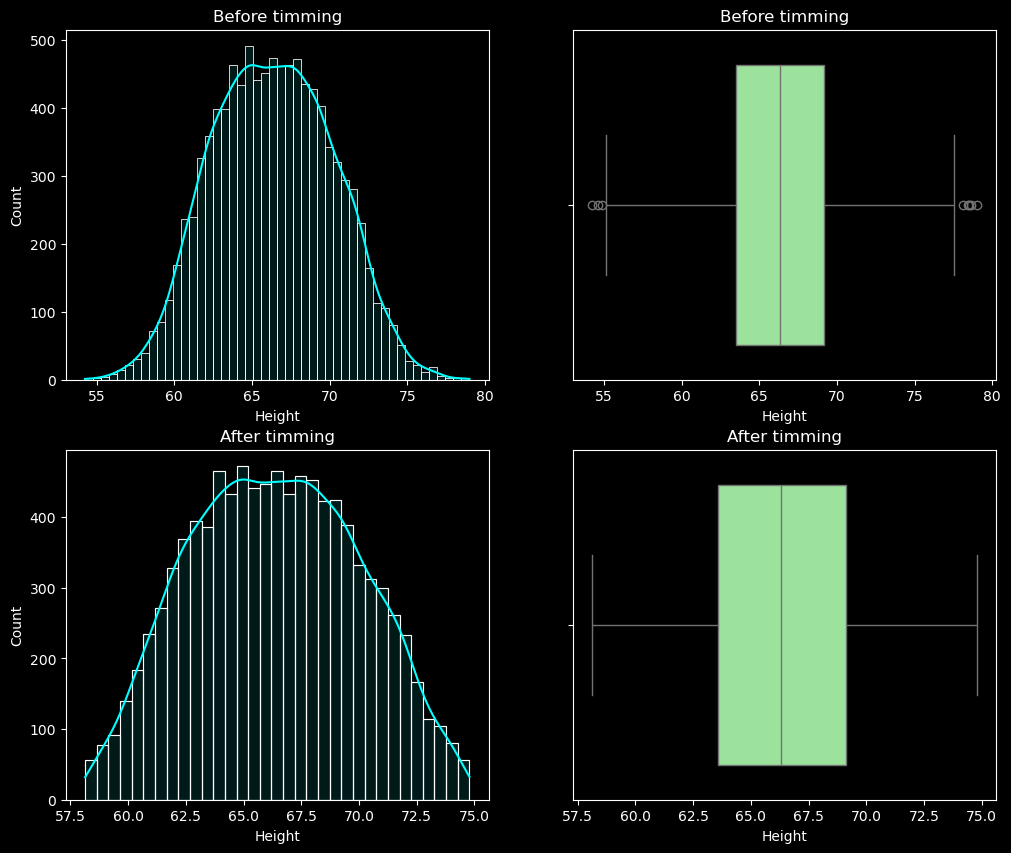

In [45]:
# plot


plt.figure(figsize=(12,10))
plt.subplot(2,2,1)
plt.title('Before timming')
sns.histplot(df['Height'],kde=True, alpha=0.1,color='cyan')



plt.subplot(2,2,2)
plt.title('Before timming')
sns.boxplot(df['Height'], orient='h',color='lightgreen')



plt.subplot(2,2,3)
plt.title('After timming')
sns.histplot(trimmed_df['Height'],kde=True, alpha=0.1,color='cyan')



plt.subplot(2,2,4)
plt.title('After timming')
sns.boxplot(trimmed_df['Height'], orient='h',color='lightgreen')

# Winsorization -- > capping using percentile method


In [46]:
upper_limit

74.7857900583366

In [47]:
lower_limit

58.13441158671655

In [48]:
capped_df = df.copy()

In [49]:
capped_df.shape

(10000, 3)

In [50]:
capped_df['Height'] = np.where( capped_df['Height'] > upper_limit ,
                               upper_limit,
                               np.where( capped_df['Height'] < lower_limit,
                                        lower_limit,
                                        df['Height']
                               )
)

In [51]:
capped_df.shape

(10000, 3)

In [52]:
capped_df.describe()

,Height,Weight
count,10000.000000,10000.000000
mean,66.366281,161.440357
std,3.795717,32.108439
min,58.134412,64.700127
25%,63.505620,135.818051
50%,66.318070,161.212928
75%,69.174262,187.169525
max,74.785790,269.989699


In [53]:
df.describe()

,Height,Weight
count,10000.000000,10000.000000
mean,66.367560,161.440357
std,3.847528,32.108439
min,54.263133,64.700127
25%,63.505620,135.818051
50%,66.318070,161.212928
75%,69.174262,187.169525
max,78.998742,269.989699


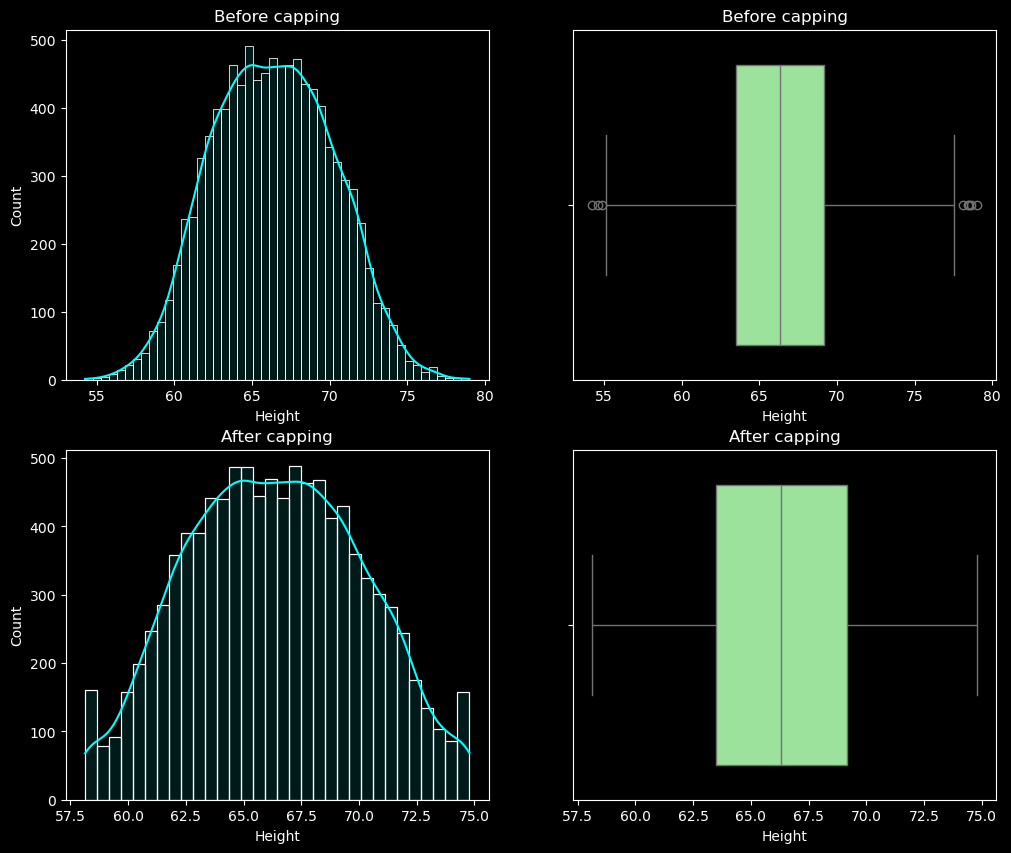

In [55]:
# plot


plt.figure(figsize=(12,10))
plt.subplot(2,2,1)
plt.title('Before capping')
sns.histplot(df['Height'],kde=True, alpha=0.1,color='cyan')



plt.subplot(2,2,2)
plt.title('Before capping')
sns.boxplot(df['Height'], orient='h',color='lightgreen')



plt.subplot(2,2,3)
plt.title('After capping')
sns.histplot(capped_df['Height'],kde=True, alpha=0.1,color='cyan')



plt.subplot(2,2,4)
plt.title('After capping')
sns.boxplot(capped_df['Height'], orient='h',color='lightgreen')

plt.show()